# 03. Curvas de fechamento

Este notebook simula o fechamento sucessivo de aeroportos na malha de referência (abril/2024) e mede como a rede se degrada. Na literatura de robustez de redes, esse tipo de remoção de nós é chamado de "ataque" (Albert, Jeong e Barabási, 2000); aqui vamos usar "fechamento".

Hipóteses testadas (`docs/problema.md`):

- **H1.** A malha é robusta a falhas aleatórias e frágil a fechamentos direcionados.
  *Refutada se* as curvas por grau ou betweenness ficarem próximas da média das remoções aleatórias.
- **H3.** A remoção adaptativa (recalculando a betweenness a cada fechamento) degrada a malha mais rápido que a remoção por grau.
  *Refutada se* a curva adaptativa não ficar abaixo da curva por grau nos primeiros fechamentos.

**Conteúdo do curso usado neste notebook**

| Conceito | Semana | Seção |
|---|---|---|
| Grau | 2 | 1 a 4 |
| Centralidade de betweenness | 4 | 1 a 4 |
| Componentes (SCC, WCC) | 4 | 1 a 4 |
| Eficiência | 4 | 1 a 3 |

As funções estão em `src/fechamentos.py`.

In [1]:
import sys
from pathlib import Path
raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(raiz / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from fechamentos import comparar_estrategias, fechados_ate
from rede import carregar_grafo, nome_curto

PASTA_FIG = raiz / "figures"
PASTA_FIG.mkdir(exist_ok=True)

CORES = {"aleatória": "#a3a29b", "grau": "#2a78d6", "betweenness": "#eb6834", "adaptativa": "#1baf7a"}
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})
pd.set_option("display.precision", 3)

G_ref = carregar_grafo(raiz / "data" / "processed" / "rede_referencia.graphml")
print(f"Malha de referência (abril/2024): {G_ref.number_of_nodes()} aeroportos e {G_ref.number_of_edges()} rotas.")

Malha de referência (abril/2024): 154 aeroportos e 816 rotas.


## 1. Estratégias e medidas

Quatro estratégias de fechamento, todas aplicadas até a rede inteira ser fechada:

| Estratégia | Ordem de fechamento |
|---|---|
| aleatória | sorteada; repetida 50 vezes com seed fixa (42) |
| grau | do maior para o menor grau total, calculado uma vez na rede intacta |
| betweenness | da maior para a menor betweenness, calculada uma vez na rede intacta |
| adaptativa | a cada passo, o aeroporto de maior betweenness **na rede que sobrou** |

Depois de cada fechamento, medimos:

- **maior SCC:** fração dos aeroportos *originais* que continuam na maior componente fortemente conexa, isto é, que ainda conseguem ir e voltar entre si;
- **eficiência global:** calculada com o n da rede original (pares com aeroporto fechado contam 0) e mostrada como fração da eficiência da rede intacta.

As duas medidas usam o tamanho original da rede, para que fechar aeroportos nunca faça uma medida subir só porque a rede ficou menor.

In [2]:
REPETICOES, SEED = 50, 42
curvas = comparar_estrategias(G_ref, repeticoes=REPETICOES, seed=SEED)
ef_intacta = curvas.loc[curvas["fechados"] == 0, "eficiência"].iloc[0]
curvas["eficiência relativa"] = curvas["eficiência"] / ef_intacta
for sufixo in [" p5", " p95"]:
    curvas["eficiência relativa" + sufixo] = curvas["eficiência" + sufixo] / ef_intacta
print(f"eficiência da rede intacta: {ef_intacta:.4f}")
print(f"linhas por estratégia: {curvas.groupby('estratégia').size().to_dict()}")

eficiência da rede intacta: 0.3909
linhas por estratégia: {'adaptativa': 155, 'aleatória': 155, 'betweenness': 155, 'grau': 155}


## 2. Curvas de fechamento (Sem. 4)

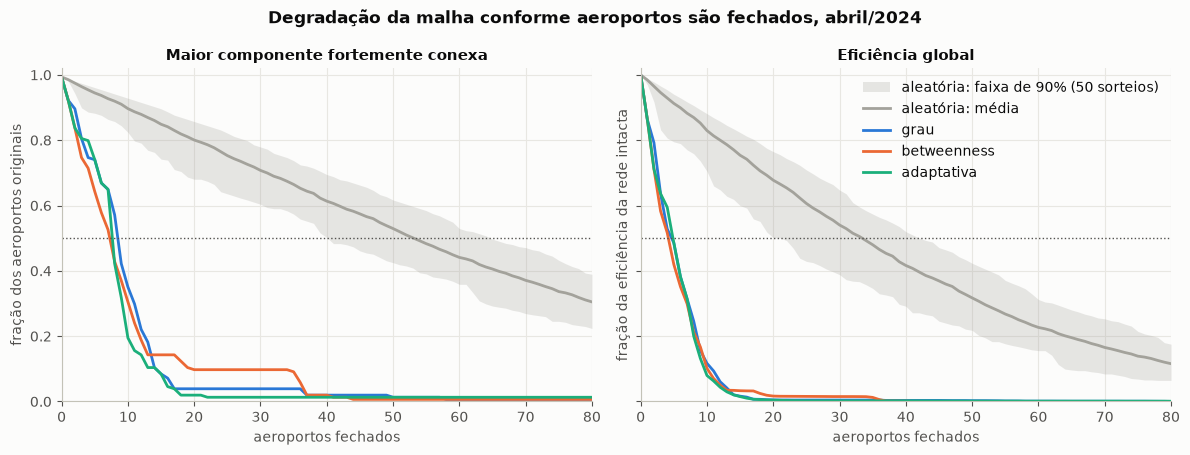

In [3]:
X_MAX = 80
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
paineis = [("maior SCC", "Maior componente fortemente conexa", "fração dos aeroportos originais"),
           ("eficiência relativa", "Eficiência global", "fração da eficiência da rede intacta")]

for ax, (medida, titulo, ylabel) in zip(eixos, paineis):
    for estrategia, cor in CORES.items():
        c = curvas[(curvas["estratégia"] == estrategia) & (curvas["fechados"] <= X_MAX)]
        if estrategia == "aleatória":
            ax.fill_between(c["fechados"], c[medida + " p5"], c[medida + " p95"], color=cor, alpha=0.25,
                            linewidth=0, label=f"aleatória: faixa de 90% ({REPETICOES} sorteios)")
            ax.plot(c["fechados"], c[medida], color=cor, linewidth=2, label="aleatória: média")
        else:
            ax.plot(c["fechados"], c[medida], color=cor, linewidth=2, label=estrategia)
    ax.axhline(0.5, color="#52514e", linestyle=":", linewidth=1)
    ax.set(title=titulo, xlabel="aeroportos fechados", ylim=(0, 1.02), xlim=(0, X_MAX))
    ax.set_ylabel(ylabel)
eixos[1].legend(frameon=False, loc="upper right")
fig.suptitle("Degradação da malha conforme aeroportos são fechados, abril/2024", fontweight="bold")
fig.tight_layout()
fig.savefig(PASTA_FIG / "03_curvas_fechamento.png", dpi=150)
plt.show()

- A diferença entre fechamentos aleatórios e direcionados é enorme. Na média aleatória (cinza), a malha perde aeroportos da maior SCC **em ritmo quase constante, um a um**. Nas três estratégias direcionadas, a maior SCC **desaba nos primeiros 10 a 15 fechamentos**.
- As três curvas direcionadas ficam **abaixo da faixa de 90% das remoções aleatórias** em todos os passos do 1º ao 80º fechamento, nas duas medidas.
- A eficiência cai ainda mais rápido que a SCC: os primeiros fechamentos não desconectam quase nada, mas alongam muito os caminhos, porque os passageiros perdem os hubs onde faziam conexão.
- Depois de uns 15 fechamentos direcionados (10% dos aeroportos), a malha está **praticamente desmontada**: sobram ilhas pequenas e a eficiência fica perto de zero.

Figura salva em `figures/03_curvas_fechamento.png`.

## 3. Quantos fechamentos bastam: H1 (Sem. 4)

In [4]:
ordem_estrategias = list(CORES)
limiares = pd.DataFrame({
    "maior SCC < 50%": {e: fechados_ate(curvas[curvas["estratégia"] == e], "maior SCC", 0.5) for e in ordem_estrategias},
    "eficiência < 50%": {e: fechados_ate(curvas[curvas["estratégia"] == e], "eficiência relativa", 0.5) for e in ordem_estrategias},
})
limiares.index.name = "estratégia"
print("número de fechamentos até cair abaixo de 50%:")
display(limiares)

marcos = [1, 5, 10, 20, 40]
for medida in ["maior SCC", "eficiência relativa"]:
    tabela = (curvas[curvas["fechados"].isin(marcos)]
              .pivot(index="estratégia", columns="fechados", values=medida).loc[ordem_estrategias].round(3))
    print(f"\n{medida} depois de k fechamentos:")
    display(tabela)

número de fechamentos até cair abaixo de 50%:


,maior SCC < 50%,eficiência < 50%
estratégia,,
aleatória,54,34
grau,9,5
betweenness,8,5
adaptativa,8,5



maior SCC depois de k fechamentos:


fechados,1,5,10,20,40
estratégia,,,,,
aleatória,0.985,0.945,0.897,0.801,0.613
grau,0.922,0.740,0.351,0.039,0.019
betweenness,0.922,0.643,0.305,0.097,0.019
adaptativa,0.922,0.740,0.195,0.019,0.013



eficiência relativa depois de k fechamentos:


fechados,1,5,10,20,40
estratégia,,,,,
aleatória,0.984,0.913,0.829,0.677,0.416
grau,0.864,0.486,0.117,0.005,0.003
betweenness,0.864,0.420,0.101,0.017,0.001
adaptativa,0.864,0.486,0.080,0.004,0.002


- Para derrubar a maior SCC abaixo de 50%, são precisos **54 fechamentos aleatórios** (35% dos aeroportos), mas só **8 ou 9 direcionados** (5% a 6%). Para cortar a eficiência pela metade, **34 aleatórios contra 5 direcionados**.
- Depois de 10 fechamentos, a malha mantém **90% da maior SCC e 83% da eficiência** se os fechamentos forem aleatórios, contra **20% a 35% da SCC e 8% a 12% da eficiência** se forem direcionados.
- **Um único fechamento já mostra a diferença:** fechar só Viracopos tira 7 pontos da maior SCC e 14% da eficiência, o mesmo dano médio de **cerca de 8 fechamentos aleatórios**.
- **Veredito sobre H1: confirmada.** As curvas direcionadas não ficam próximas da média aleatória; ficam abaixo da faixa de 90% das remoções aleatórias em todos os passos do 1º ao 80º fechamento. É o comportamento esperado de uma rede com distribuição de grau concentrada (notebook 01): um aeroporto sorteado quase sempre é periférico, e fechá-lo afeta pouco; os poucos hubs concentram as ligações.

## 4. Ordem dos fechamentos: H3 (Sem. 2 e 4)

In [5]:
alvos = ["grau", "betweenness", "adaptativa"]
sequencias = {}
for e in alvos:
    c = curvas[(curvas["estratégia"] == e) & (curvas["fechados"].between(1, 12))].copy()
    queda = curvas[curvas["estratégia"] == e]["maior SCC"].diff().loc[c.index]
    sequencias[e] = [f"{nome_curto(G_ref, a)} ({100 * q:+.0f} p.p.)" for a, q in zip(c["aeroporto"], queda)]
seq = pd.DataFrame(sequencias, index=range(1, 13))
seq.index.name = "fechamento"
print("aeroporto fechado em cada passo e variação da maior SCC (pontos percentuais):")
with pd.option_context("display.max_colwidth", None):
    display(seq)

aeroporto fechado em cada passo e variação da maior SCC (pontos percentuais):


,grau,betweenness,adaptativa
fechamento,,,
1,Viracopos (SP) (-7 p.p.),Viracopos (SP) (-7 p.p.),Viracopos (SP) (-7 p.p.)
2,Guarulhos (SP) (-3 p.p.),Tancredo Neves (MG) (-8 p.p.),Tancredo Neves (MG) (-8 p.p.)
3,Tancredo Neves (MG) (-9 p.p.),Eduardo Gomes (AM) (-9 p.p.),Guarulhos (SP) (-3 p.p.)
4,Congonhas (SP) (-6 p.p.),Guarulhos (SP) (-3 p.p.),Brasília (DF) (-1 p.p.)
5,Brasília (DF) (-1 p.p.),Guararapes (PE) (-7 p.p.),Congonhas (SP) (-6 p.p.)
6,Guararapes (PE) (-7 p.p.),Val de Cans (PA) (-6 p.p.),Guararapes (PE) (-7 p.p.)
7,Galeão (RJ) (-2 p.p.),Marechal Rondon (MT) (-5 p.p.),Galeão (RJ) (-2 p.p.)
8,Val de Cans (PA) (-8 p.p.),Brasília (DF) (-10 p.p.),Marechal Rondon (MT) (-23 p.p.)
9,Eduardo Gomes (AM) (-15 p.p.),Salgado Filho (RS) (-6 p.p.),Eduardo Gomes (AM) (-10 p.p.)


In [6]:
comparacao = (curvas[curvas["estratégia"].isin(["grau", "adaptativa", "betweenness"]) & curvas["fechados"].between(1, 12)]
              .pivot(index="fechados", columns="estratégia", values="maior SCC")[["grau", "betweenness", "adaptativa"]])
comparacao["adaptativa - grau"] = comparacao["adaptativa"] - comparacao["grau"]
comparacao

estratégia,grau,betweenness,adaptativa,adaptativa - grau
fechados,,,,
1,0.922,0.922,0.922,0.000
2,0.896,0.838,0.838,-0.058
3,0.805,0.747,0.805,0.000
4,0.747,0.714,0.799,0.052
5,0.740,0.643,0.740,0.000
6,0.669,0.578,0.669,0.000
7,0.649,0.526,0.649,0.000
8,0.571,0.429,0.422,-0.149
9,0.422,0.370,0.318,-0.104


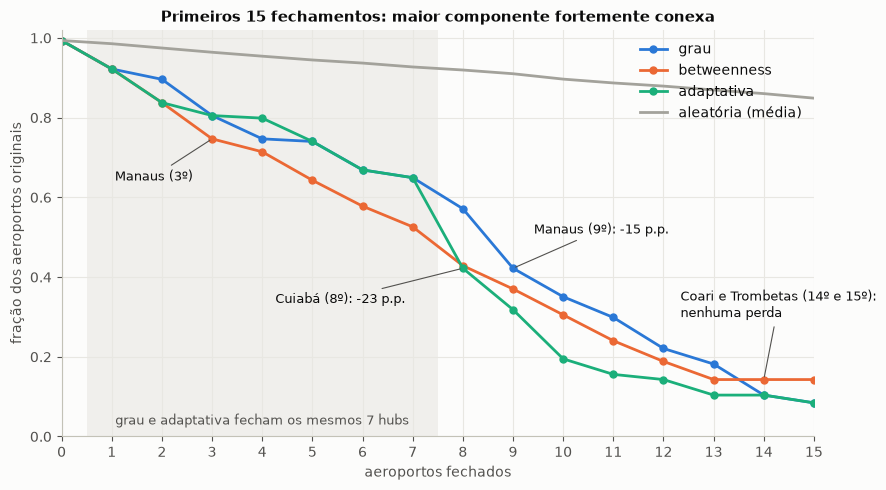

In [7]:
K = 15
fig, ax = plt.subplots(figsize=(9, 5))
for e in ["grau", "betweenness", "adaptativa"]:
    c = curvas[(curvas["estratégia"] == e) & (curvas["fechados"] <= K)]
    ax.plot(c["fechados"], c["maior SCC"], color=CORES[e], linewidth=2, marker="o", markersize=5, label=e)
c = curvas[(curvas["estratégia"] == "aleatória") & (curvas["fechados"] <= K)]
ax.plot(c["fechados"], c["maior SCC"], color=CORES["aleatória"], linewidth=2, label="aleatória (média)")

def marcar(estrategia, passo, texto, dx, dy):
    linha = curvas[(curvas["estratégia"] == estrategia) & (curvas["fechados"] == passo)].iloc[0]
    ax.annotate(texto, (passo, linha["maior SCC"]), xytext=(dx, dy), textcoords="offset points", fontsize=9,
                color="#0b0b0b", arrowprops=dict(arrowstyle="-", color="#52514e", linewidth=0.8))

marcar("betweenness", 3, "Manaus (3º)", -70, -30)
marcar("adaptativa", 8, "Cuiabá (8º): -23 p.p.", -135, -25)
marcar("grau", 9, "Manaus (9º): -15 p.p.", 15, 25)
marcar("betweenness", 14, "Coari e Trombetas (14º e 15º):\nnenhuma perda", -60, 45)
ax.axvspan(0.5, 7.5, color="#e8e7e2", alpha=0.6, linewidth=0)
ax.text(4, 0.03, "grau e adaptativa fecham os mesmos 7 hubs", ha="center", fontsize=9, color="#52514e")
ax.set(title="Primeiros 15 fechamentos: maior componente fortemente conexa",
       xlabel="aeroportos fechados", ylabel="fração dos aeroportos originais", xlim=(0, K), ylim=(0, 1.02))
ax.set_xticks(range(0, K + 1))
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig(PASTA_FIG / "03_primeiros_fechamentos.png", dpi=150)
plt.show()

- **Nos 7 primeiros fechamentos, grau e adaptativa fecham os mesmos 7 hubs** (Viracopos, Guarulhos, Confins, Congonhas, Brasília, Recife e Galeão), só em outra ordem. As curvas coincidem nos passos 1, 3, 5, 6 e 7; no passo 2 a adaptativa está 6 pontos abaixo, e no passo 4, 5 pontos *acima*.
- **A partir do 8º fechamento, a adaptativa se separa.** Com os hubs fechados, a betweenness recalculada aponta para **Cuiabá**, cujo fechamento sozinho tira **23 pontos** da maior SCC (35 aeroportos). Depois vêm **Manaus** (-10) e **Belém** (-12). No 10º fechamento, a adaptativa deixa 20% da SCC, contra 35% na estratégia por grau.
- **A betweenness calculada uma vez só é a mais destrutiva entre o 3º e o 7º fechamento**, porque fecha Manaus logo no 3º passo. Mas ela envelhece: depois que a rede fragmenta, continua fechando aeroportos que já estão isolados. Coari e Trombetas, 14º e 15º da lista, saem **sem nenhuma perda**. É exatamente o que a versão adaptativa corrige.
- **Veredito sobre H3: confirmada só em parte.** Pelo critério que definimos, a adaptativa não fica abaixo da curva por grau nos primeiros 7 fechamentos, porque as duas fecham o mesmo núcleo. Ela passa a degradar a malha mais rápido do 8º fechamento em diante, quando passa a mirar as pontes.
- **Ligação com o notebook 02:** os primeiros alvos de qualquer estratégia são os hubs do núcleo. A maior queda isolada, porém, vem de uma **ponte da borda do núcleo** (Cuiabá, k = 8) depois que o núcleo já caiu. Enquanto o núcleo está de pé, ele compensa as perdas; quando ele cai, as pontes viram o ponto fraco.

Figura salva em `figures/03_primeiros_fechamentos.png`.

## Resumo

- **H1 confirmada:** 8 ou 9 fechamentos direcionados derrubam a maior SCC abaixo de 50%; aleatoriamente, são precisos 54. Fechar só Viracopos equivale a cerca de 8 fechamentos aleatórios.
- **H3 confirmada em parte:** a adaptativa só se destaca a partir do 8º fechamento, quando passa a fechar as pontes (Cuiabá, Manaus, Belém); antes disso, ela e a estratégia por grau fecham os mesmos 7 hubs.
- A betweenness fixa é a mais destrutiva no começo, mas perde eficácia depois que a rede fragmenta.

**Limite desta análise:** fechar dezenas de aeroportos ao mesmo tempo não é um cenário realista; as curvas servem para medir a estrutura da malha. A pergunta prática (qual aeroporto, **fechado sozinho**, mais desconecta a malha ou mais aumenta as escalas entre capitais) é o tema do próximo notebook, o ranking de aeroportos críticos.